In [1]:
import pandas as pd
import numpy as np
import mlflow
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from sklearn.metrics import precision_recall_curve


import optuna
import shap
import matplotlib.pyplot as plt

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Modeling")

c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='mlflow-artifacts:/3', creation_time=1785101030275, effective_trace_archival_retention=None, experiment_id='3', last_update_time=1785101030275, lifecycle_stage='active', name='Modeling', tags={}, trace_location=None, workspace='default'>

In [2]:
path = "../data/processed/Bank_Churn_clean.csv"
df = pd.read_csv(path)


TARGET = "Exited"
X = df.drop(columns=[TARGET])
y = df["Exited"]

X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, stratify= y, random_state=42)


ohe = OneHotEncoder( handle_unknown='ignore')
cat_cols = ['Gender', 'Geography']

ohe.fit(X_train[cat_cols])
X_train_ohe = ohe.transform(X_train[cat_cols])
X_test_ohe = ohe.transform(X_test[cat_cols])

ohe_cols = ohe.get_feature_names_out(cat_cols)
X_train[ohe_cols] = pd.DataFrame(X_train_ohe.toarray(), columns=ohe_cols, index=X_train.index)
X_test[ohe_cols] = pd.DataFrame(X_test_ohe.toarray(), columns=ohe_cols, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [3]:
mlflow.sklearn.autolog()


def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 600),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'min_samples_split': trial.suggest_int('min_samples_split',2,10),
        'random_state': 42
    }

    with mlflow.start_run(nested=True):
        model = RandomForestClassifier(**params)
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        recall = recall_score(y_test, y_pred)
        return recall


with mlflow.start_run():
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=20)

    mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})
    mlflow.log_metric("best_recall", study.best_value)

[I 2026-07-27 14:12:57,224] A new study created in memory with name: no-name-e6db3a71-b928-4003-9e38-641195ccb86b
2026/07/27 14:12:57 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2026/07/27 14:13:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 14:13:12,059] Trial 0 finished with value: 0.44963144963144963 and pa

🏃 View run mercurial-croc-222 at: http://localhost:5000/#/experiments/3/runs/7473080cd9894c2cb65bdad81729f00e
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 14:13:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 14:13:22,326] Trial 1 finished with value: 0.40294840294840295 and parameters: {'n_estimators': 447, 'max_depth': 7, 'min_samples_leaf': 6, 'max_features': 'log2', 'min_samples_split': 8}. Best is trial 0 with value: 0.44963144963144963.
2026/07/27 14:13:22 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracki

🏃 View run upset-bat-345 at: http://localhost:5000/#/experiments/3/runs/75c8348648ab4019980c76ea805935a9
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 14:13:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 14:13:32,865] Trial 2 finished with value: 0.4152334152334152 and parameters: {'n_estimators': 145, 'max_depth': 5, 'min_samples_leaf': 2, 'max_features': None, 'min_samples_split': 7}. Best is trial 0 with value: 0.44963144963144963.
2026/07/27 14:13:32 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking.

🏃 View run placid-newt-966 at: http://localhost:5000/#/experiments/3/runs/8f7fd741093a47f89f9eeb2ec08076e1
🧪 View experiment at: http://localhost:5000/#/experiments/3


... (30 outputs left out)

2026/07/27 14:17:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 14:17:19,007] Trial 18 finished with value: 0.4594594594594595 and parameters: {'n_estimators': 178, 'max_depth': 12, 'min_samples_leaf': 3, 'max_features': None, 'min_samples_split': 6}. Best is trial 11 with value: 0.4742014742014742.
2026/07/27 14:17:19 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Trackin

🏃 View run amazing-kit-305 at: http://localhost:5000/#/experiments/3/runs/9088f1b9574f4ddf8e1ebdc9dbb16afc
🧪 View experiment at: http://localhost:5000/#/experiments/3


2026/07/27 14:17:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(
[I 2026-07-27 14:17:43,699] Trial 19 finished with value: 0.4643734643734644 and parameters: {'n_estimators': 406, 'max_depth': 14, 'min_samples_leaf': 5, 'max_features': None, 'min_samples_split': 4}. Best is trial 11 with value: 0.4742014742014742.


🏃 View run adorable-wolf-846 at: http://localhost:5000/#/experiments/3/runs/2d27f25c421b43afa9c4cdada0998453
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run funny-newt-448 at: http://localhost:5000/#/experiments/3/runs/5b98323156964796a7874347ce9148d7
🧪 View experiment at: http://localhost:5000/#/experiments/3


In [4]:
best_params = study.best_params
print("Meilleurs hyperparamètres:", best_params)

Meilleurs hyperparamètres: {'n_estimators': 225, 'max_depth': 15, 'min_samples_leaf': 3, 'max_features': None, 'min_samples_split': 5}


In [5]:
model_name = "Rf_churn"
model_version = "Version 1"
model_uri = f"models:/{model_name}/{model_version}"
# Normalize model_version (accept "Version 1", "1", or stage names)
mv = model_version
if isinstance(mv, str) and mv.lower().startswith("version "):
    mv = mv.split(" ", 1)[1].strip()

# Map stage names to proper case
stage_map = {"staging": "Staging", "production": "Production", "archived": "Archived"}

if isinstance(mv, str) and mv.isdigit():
    model_uri = f"models:/{model_name}/{mv}"
elif isinstance(mv, str) and mv.lower() in stage_map:
    model_uri = f"models:/{model_name}/{stage_map[mv.lower()]}"
else:
    raise ValueError(f"Invalid model_version '{model_version}'. Use numeric version (e.g. '1'), 'Version 1', or stage: Staging/Production/Archived.")

model = mlflow.sklearn.load_model(model_uri)

In [6]:
# 3. Calcul des valeurs SHAP
# TreeExplainer est optimisé pour les modèles d'arbres comme Random Forest
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# En classification binaire, SHAP génère des valeurs pour la classe 0 et la classe 1.
# On sélectionne les valeurs pour la classe 1 (généralement la classe positive).
shap_values_class1 = shap_values[:, :, 1]


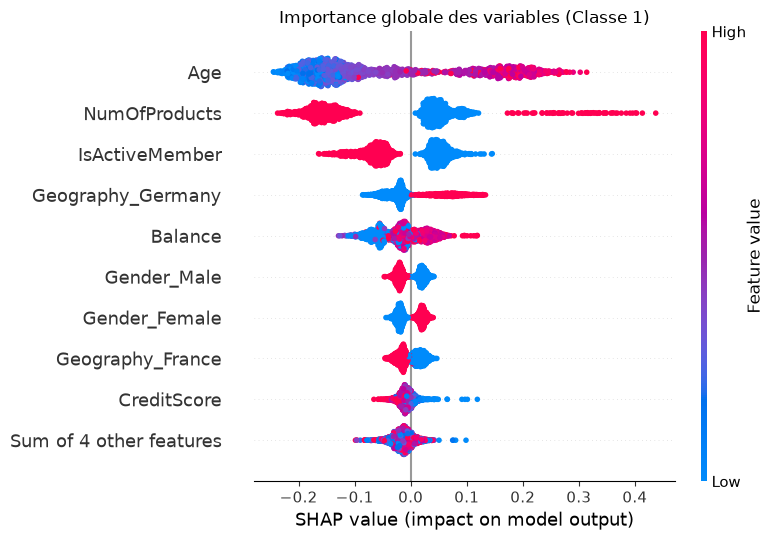

In [7]:
# 4. Génération des visualisations
# Graphique 1 : Résumé global (Beeswarm)
plt.figure()
shap.plots.beeswarm(shap_values_class1, show=False)
plt.title("Importance globale des variables (Classe 1)")
plt.tight_layout()
plt.show()

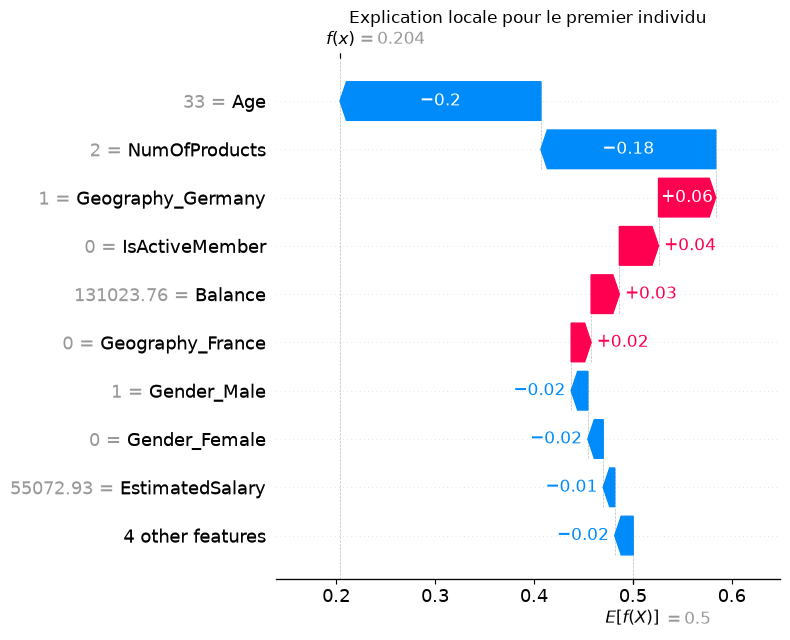

In [11]:
# Graphique 2 : Explication locale (Waterfall pour le 1er individu)
plt.figure()
shap.plots.waterfall(shap_values_class1[1], show=False)
plt.title("Explication locale pour le premier individu")
plt.tight_layout()
plt.show()

In [20]:
y_proba = model.predict_proba(X_test_scaled)[:,1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)

c:\Users\DELL\Desktop\Projet Data\Data Science\.env\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


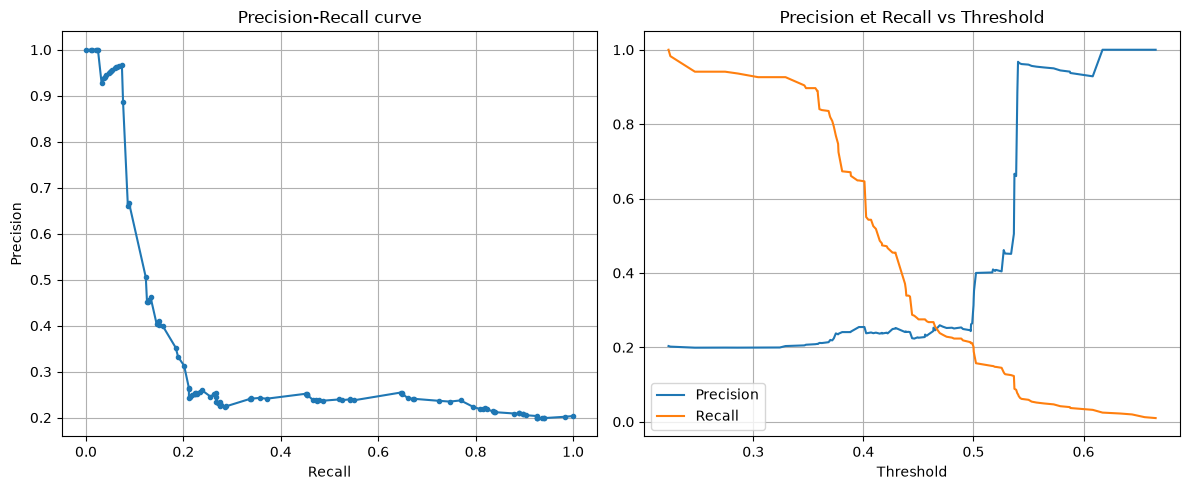

In [22]:
# Visualisation : courbe PR et Precision/Recall en fonction du seuil
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(recalls, precisions, marker='.')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall curve")
plt.grid(True)

plt.subplot(1,2,2)
# precision_recall_curve retourne len(thresholds) = len(precisions)-1 = len(recalls)-1
plt.plot(thresholds, precisions[:-1], label="Precision")
plt.plot(thresholds, recalls[:-1], label="Recall")
plt.xlabel("Threshold")
plt.title("Precision et Recall vs Threshold")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
C_FP = 50          # coût d'une fausse alerte (action de rétention)
C_FN = 1200 * 0.30 # coût d'un churner raté = LTV × taux de succès

# Nombre réel de churners dans votre jeu de test
P = (y_test == 1).sum()

best = None
for p, r, t in zip(precisions[:-1], recalls[:-1], thresholds):
    tp = r * P
    fn = P - tp
    predicted_pos = tp / p if p > 0 else 0
    fp = predicted_pos - tp
    net_impact = tp * 0.30 * 1200 - predicted_pos * 50   # même formule que le simulateur
    cost_total = fp * C_FP + fn * C_FN

    if best is None or net_impact > best["net_impact"]:
        best = dict(threshold=t, precision=p, recall=r, net_impact=net_impact, cost_total=cost_total)

print(best)

{'threshold': np.float64(0.3749965549099491), 'precision': np.float64(0.23748103186646433), 'recall': np.float64(0.769041769041769), 'net_impact': np.float64(46779.999999999985), 'cost_total': np.float64(84090.0)}
